In [7]:
from __future__ import annotations
import sys
import streamlit as st

# 1. Fake the removed 'cache' attribute to prevent streamlit-jupyter from crashing
if not hasattr(st, "cache"):
    st.cache = lambda x: x

# 2. Safely initialize the notebook patcher now
from streamlit_jupyter import StreamlitPatcher

StreamlitPatcher().jupyter()

# 3. Rest of your notebook code
st.title("My Notebook App")


# My Notebook App

In [2]:
%pip install rasterio geopandas folium matplotlib numpy pillow

  Using cached rasterio-1.5.2-cp313-cp313-win_amd64.whl.metadata (8.9 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
  Using cached pillow-13.0.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached affine-3.0.1-py3-none-any.whl.metadata (4.5 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp313-cp313-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached charset_normal


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
from pathlib import Path
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling, transform_bounds, calculate_default_transform
from rasterio.transform import array_bounds
import matplotlib.pyplot as plt
import folium
from folium import LayerControl
from folium.raster_layers import ImageOverlay
from PIL import Image

In [16]:


# 1. Initialize your data folder properly
DATA_FOLDER = Path(".")  # Defaults to current directory, change as needed

# 2. Fixed the accidental spaces inside the string paths
date1_files = { 
    "Green": "t1/scene_G.tif", 
    "Red": "t1/scene_R.tif",      # Fixed spaces
    "RedEdge": "t1/scene_RE.tif",  # Fixed spaces
    "NIR": "t1/scene_NIR.tif",    # Fixed spaces
} 

date2_files = { 
    "Green": "t2/scene_G.tif",     # Fixed "t2_/ " typo
    "Red": "t2/scene_R.tif",       # Fixed spaces
    "RedEdge": "t2/scene_RE.tif",  # Added assumed 't2/' prefix if it belongs there
    "NIR": "t2/scene_NIR.tif", 
} 

for label, files in [("Date 1", date1_files), ("Date 2", date2_files)]: 
    for band, relative_path in files.items(): 
        
        # 3. Combine the base DATA_FOLDER with the string path to create a Path object
        full_path = DATA_FOLDER / relative_path 
        
        # 4. Now .exists() will work perfectly
        if not full_path.exists(): 
            print(f"Missing {label} {band}: {full_path}")


In [17]:
def load_band(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float32")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
        meta = {
            "crs": src.crs, "transform": src.transform,
            "width": src.width, "height": src.height,
            "bounds": src.bounds, "nodata": src.nodata
        }
    return arr, meta

date1, meta1, date2, meta2 = {}, {}, {}, {}
for band in date1_files:
    date1[band], meta1[band] = load_band(date1_files[band])
    date2[band], meta2[band] = load_band(date2_files[band])

print("Date 1 Red shape:", date1["Red"].shape, "CRS:", meta1["Red"]["crs"])
print("Date 2 Red shape:", date2["Red"].shape, "CRS:", meta2["Red"]["crs"])

Date 1 Red shape: (100, 100) CRS: EPSG:32633
Date 2 Red shape: (100, 100) CRS: EPSG:32633


In [18]:
def check_alignment(metadata, label):
    ref = metadata["Red"]
    for band, m in metadata.items():
        match = (m["crs"] == ref["crs"] and m["transform"] == ref["transform"]
                 and m["width"] == ref["width"] and m["height"] == ref["height"])
        print(f"{label} {band} matches Red grid: {match}")

check_alignment(meta1, "Date 1")
check_alignment(meta2, "Date 2")

Date 1 Green matches Red grid: True
Date 1 Red matches Red grid: True
Date 1 RedEdge matches Red grid: True
Date 1 NIR matches Red grid: True
Date 2 Green matches Red grid: True
Date 2 Red matches Red grid: True
Date 2 RedEdge matches Red grid: True
Date 2 NIR matches Red grid: True


In [19]:
reference = meta1["Red"]

def align_to_reference(array, source_meta, ref_meta):
    result = np.full((ref_meta["height"], ref_meta["width"]), np.nan, dtype="float32")
    reproject(
        source=array, destination=result,
        src_transform=source_meta["transform"], src_crs=source_meta["crs"],
        src_nodata=np.nan,
        dst_transform=ref_meta["transform"], dst_crs=ref_meta["crs"],
        dst_nodata=np.nan, resampling=Resampling.bilinear
    )
    return result

date2_aligned = {
    band: align_to_reference(date2[band], meta2[band], reference)
    for band in date2
}
print("Reference grid:", date1["Red"].shape)
print("Date 2 aligned grid:", date2_aligned["Red"].shape)

Reference grid: (100, 100)
Date 2 aligned grid: (100, 100)


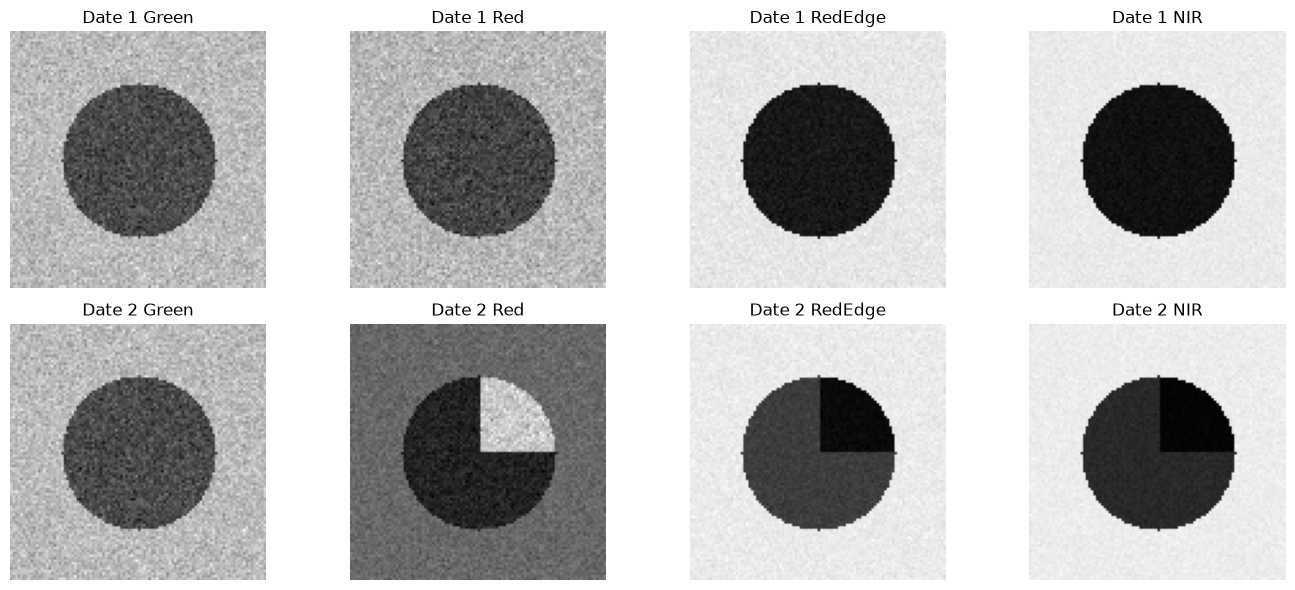

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for j, band in enumerate(["Green", "Red", "RedEdge", "NIR"]):
    axes[0, j].imshow(date1[band], cmap="gray")
    axes[0, j].set_title(f"Date 1 {band}")
    axes[0, j].axis("off")
    axes[1, j].imshow(date2_aligned[band], cmap="gray")
    axes[1, j].set_title(f"Date 2 {band}")
    axes[1, j].axis("off")
plt.tight_layout()
plt.show()

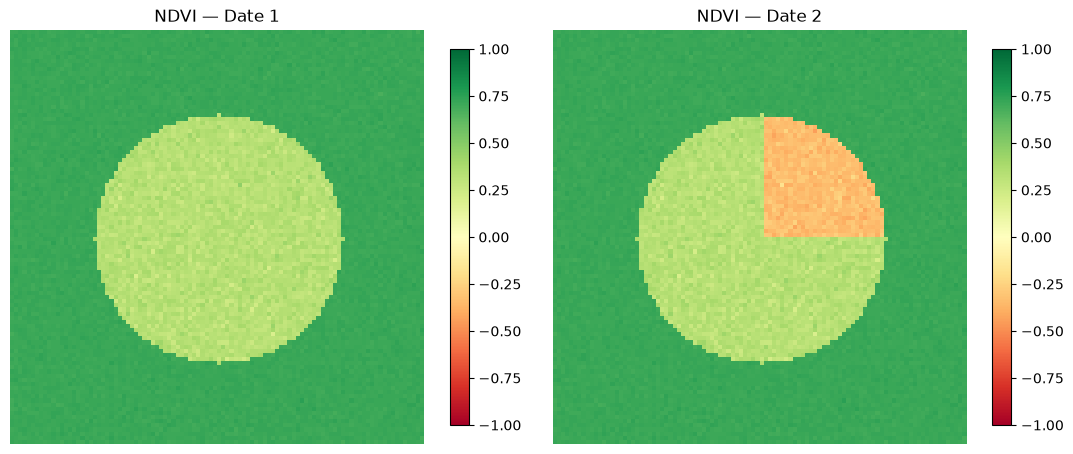

In [26]:
def calculate_ndvi(red, nir):
    denominator = nir + red
    result = np.full(red.shape, np.nan, dtype="float32")
    valid = np.isfinite(red) & np.isfinite(nir) & (denominator != 0)
    result[valid] = (nir[valid] - red[valid]) / denominator[valid]
    return result

ndvi1 = calculate_ndvi(date1["Red"], date1["NIR"])
ndvi2 = calculate_ndvi(date2_aligned["Red"], date2_aligned["NIR"])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, arr, title in [(axes[0], ndvi1, "NDVI — Date 1"), (axes[1], ndvi2, "NDVI — Date 2")]:
    im = ax.imshow(arr, cmap="RdYlGn", vmin=-1, vmax=1)
    ax.set_title(title); ax.axis("off")
    fig.colorbar(im, ax=ax, shrink=.8)
plt.tight_layout()
plt.show()

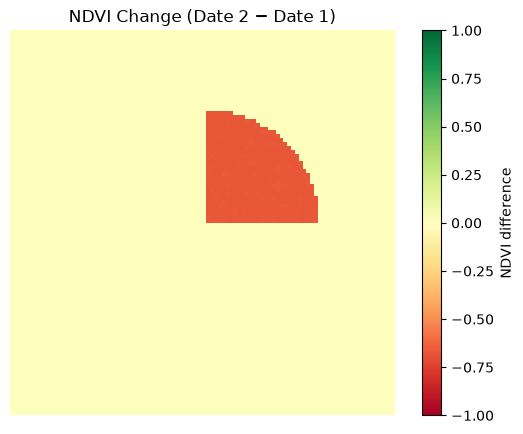

Valid pixels: 10000
Mean change: -0.0449
Median change: 0.0
Increased pixels: 0
Decreased pixels: 675


In [22]:
ndvi_change = ndvi2 - ndvi1

plt.figure(figsize=(7, 5))
plt.imshow(ndvi_change, cmap="RdYlGn", vmin=-1, vmax=1)
plt.title("NDVI Change (Date 2 − Date 1)")
plt.colorbar(label="NDVI difference")
plt.axis("off")
plt.show()

valid = ndvi_change[np.isfinite(ndvi_change)]
print("Valid pixels:", valid.size)
if valid.size:
    print("Mean change:", round(float(valid.mean()), 4))
    print("Median change:", round(float(np.median(valid)), 4))
    print("Increased pixels:", int((valid > 0).sum()))
    print("Decreased pixels:", int((valid < 0).sum()))


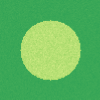
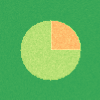
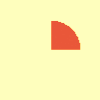

In [28]:
def add_overlay(map_obj, arr, ref_meta, name, show=False, max_side=800):
    h, w = arr.shape
    scale = min(1.0, max_side / max(h, w))
    out_h, out_w = max(1, int(h * scale)), max(1, int(w * scale))
    bounds = array_bounds(h, w, ref_meta["transform"])
    out_transform, _, _ = calculate_default_transform(
        ref_meta["crs"], "EPSG:4326", w, h, *bounds,
        dst_width=out_w, dst_height=out_h
    )
    out = np.full((out_h, out_w), np.nan, dtype="float32")
    reproject(
        source=arr, destination=out,
        src_transform=ref_meta["transform"], src_crs=ref_meta["crs"],
        src_nodata=np.nan,
        dst_transform=out_transform, dst_crs="EPSG:4326",
        dst_nodata=np.nan, resampling=Resampling.bilinear
    )
    rgba = plt.get_cmap("RdYlGn")(np.clip((out + 1) / 2, 0, 1))
    rgba[~np.isfinite(out), 3] = 0
    rgba = (rgba * 255).astype("uint8")
    west, south, east, north = array_bounds(out_h, out_w, out_transform)
    ImageOverlay(
        rgba,
        bounds=[[south, west], [north, east]],
        name=name, opacity=.75, show=show
    ).add_to(map_obj)

west, south, east, north = transform_bounds(
    reference["crs"], "EPSG:4326", *reference["bounds"]
)
center = [(south + north) / 2, (west + east) / 2]
m = folium.Map(location=center, zoom_start=13, tiles="OpenStreetMap")

add_overlay(m, ndvi1, reference, "NDVI — Date 1", show=True)
add_overlay(m, ndvi2, reference, "NDVI — Date 2")
add_overlay(m, ndvi_change, reference, "NDVI Change")
LayerControl(collapsed=False).add_to(m)
m

In [ ]:
%pip install streamlit

  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached starlette-1.10.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached anyio-4.16.0-py3-none-any.whl.metadata (4.7 kB)
  Using cached python_multipart-0.0.33-py3-none-any.whl.metadata (6.3 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.2 MB 624.6 kB/s eta 0:00:18
   -- ------------------------------------- 0.8/11.2 MB 705.2 kB/s eta 0:00:15
   -- ------------------------------------- 0.8/11.2 MB 705.2 kB/s eta 0:00:15
   ----


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
%pip install streamlit-folium

   ---------------------------------------- 0.0/536.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/536.9 kB ? eta -:--:--
   ---------------------------------------- 536.9/536.9 kB 3.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
output_path = Path("ndvi_change.tif")
with rasterio.open(date1_files["Red"]) as src:
    profile = src.profile.copy()
profile.update(count=1, dtype="float32", nodata=np.nan, compress="deflate")

with rasterio.open(output_path, "w", **profile) as dst:
    dst.write(ndvi_change.astype("float32"), 1)

print("Saved:", output_path.resolve())

Saved: C:\Users\ancys\Documents\aethra\notebook\ndvi_change.tif


In [ ]:


from io import BytesIO
from typing import Dict, Tuple

import folium
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import streamlit as st
from folium.raster_layers import ImageOverlay
from PIL import Image
from rasterio.io import MemoryFile
from rasterio.transform import array_bounds
from rasterio.warp import (
    Resampling,
    calculate_default_transform,
    reproject,
    transform_bounds,
)
from streamlit_folium import st_folium


BANDS = ("Green", "Red", "RedEdge", "NIR")
DATE_LABELS = ("Date 1 — baseline", "Date 2 — comparison")


st.set_page_config(page_title="Wetland & Vegetation Monitor", layout="wide")
st.title("Wetland & Vegetation Monitor")
st.caption(
    "A small Streamlit interface for checking eight single-band GeoTIFFs, "
    "calculating NDVI for two dates, and viewing NDVI change."
)

st.info(
    "This tool calculates NDVI from Red and NIR bands. Green and RedEdge are "
    "accepted and checked, but are not used in the NDVI formula. Results are "
    "indicators, not a definitive diagnosis of wetland degradation."
)


def read_uploaded_tif(uploaded_file) -> Tuple[np.ndarray, dict]:
    """Read one uploaded single-band GeoTIFF from its in-memory bytes."""
    if uploaded_file is None:
        raise ValueError("A file is missing.")

    with MemoryFile(uploaded_file.getvalue()) as memfile:
        with memfile.open() as src:
            if src.count != 1:
                raise ValueError(
                    f"{uploaded_file.name} has {src.count} bands; expected 1."
                )
            if src.crs is None:
                raise ValueError(f"{uploaded_file.name} has no CRS metadata.")

            array = src.read(1).astype("float32")
            nodata = src.nodata
            if nodata is not None:
                if np.isnan(nodata):
                    array[~np.isfinite(array)] = np.nan
                else:
                    array[array == nodata] = np.nan

            metadata = {
                "crs": src.crs,
                "transform": src.transform,
                "width": src.width,
                "height": src.height,
                "bounds": src.bounds,
                "nodata": nodata,
                "profile": src.profile.copy(),
            }
    return array, metadata


def same_grid(meta_a: dict, meta_b: dict) -> bool:
    return (
        meta_a["crs"] == meta_b["crs"]
        and meta_a["transform"] == meta_b["transform"]
        and meta_a["width"] == meta_b["width"]
        and meta_a["height"] == meta_b["height"]
    )


def align_to_reference(array: np.ndarray, source_meta: dict, ref_meta: dict) -> np.ndarray:
    """Reproject/resample an array onto the reference raster grid."""
    output = np.full(
        (ref_meta["height"], ref_meta["width"]), np.nan, dtype="float32"
    )
    reproject(
        source=array,
        destination=output,
        src_transform=source_meta["transform"],
        src_crs=source_meta["crs"],
        src_nodata=np.nan,
        dst_transform=ref_meta["transform"],
        dst_crs=ref_meta["crs"],
        dst_nodata=np.nan,
        resampling=Resampling.bilinear,
    )
    return output


def calculate_ndvi(red: np.ndarray, nir: np.ndarray) -> np.ndarray:
    denominator = nir + red
    result = np.full(red.shape, np.nan, dtype="float32")
    valid = np.isfinite(red) & np.isfinite(nir) & (denominator != 0)
    result[valid] = (nir[valid] - red[valid]) / denominator[valid]
    return result


def make_preview_png(array: np.ndarray, vmin: float, vmax: float) -> bytes:
    """Create a small color preview for the Folium map."""
    cmap = plt.get_cmap("RdYlGn")
    normalized = np.clip((array - vmin) / (vmax - vmin), 0, 1)
    rgba = cmap(np.nan_to_num(normalized, nan=0.0))
    rgba[~np.isfinite(array), 3] = 0
    image_array = (rgba * 255).astype("uint8")
    image = Image.fromarray(image_array, mode="RGBA")
    buffer = BytesIO()
    image.save(buffer, format="PNG")
    return buffer.getvalue()


def add_raster_overlay(
    map_object: folium.Map,
    array: np.ndarray,
    reference_meta: dict,
    layer_name: str,
    vmin: float,
    vmax: float,
    show: bool = False,
) -> None:
    height, width = array.shape
    bounds = array_bounds(height, width, reference_meta["transform"])
    max_side = 800
    scale = min(1.0, max_side / max(height, width))
    out_height = max(1, int(height * scale))
    out_width = max(1, int(width * scale))

    dst_transform, _, _ = calculate_default_transform(
        reference_meta["crs"],
        "EPSG:4326",
        width,
        height,
        *bounds,
        dst_width=out_width,
        dst_height=out_height,
    )
    preview = np.full((out_height, out_width), np.nan, dtype="float32")
    reproject(
        source=array,
        destination=preview,
        src_transform=reference_meta["transform"],
        src_crs=reference_meta["crs"],
        src_nodata=np.nan,
        dst_transform=dst_transform,
        dst_crs="EPSG:4326",
        dst_nodata=np.nan,
        resampling=Resampling.bilinear,
    )
    west, south, east, north = array_bounds(
        out_height, out_width, dst_transform
    )
    ImageOverlay(
        image=make_preview_png(preview, vmin, vmax),
        bounds=[[south, west], [north, east]],
        name=layer_name,
        opacity=0.75,
        show=show,
    ).add_to(map_object)


def file_inputs(date_title: str, key_prefix: str) -> Dict[str, object]:
    st.subheader(date_title)
    cols = st.columns(4)
    uploads = {}
    for column, band in zip(cols, BANDS):
        with column:
            uploads[band] = st.file_uploader(
                f"{band} band (.tif/.tiff)",
                type=["tif", "tiff"],
                key=f"{key_prefix}_{band}",
                help=f"Upload the single-band {band} GeoTIFF for this date.",
            )
    return uploads


date1_uploads = file_inputs(DATE_LABELS[0], "date1")
date2_uploads = file_inputs(DATE_LABELS[1], "date2")

run_analysis = st.button("Validate & compare", type="primary", use_container_width=True)

if run_analysis:
    all_uploads = {
        "Date 1": date1_uploads,
        "Date 2": date2_uploads,
    }
    missing = [
        f"{date_label} — {band}"
        for date_label, band_uploads in all_uploads.items()
        for band, uploaded in band_uploads.items()
        if uploaded is None
    ]

    if missing:
        st.error("Please upload all eight files before running the comparison.")
        st.write("Missing:", ", ".join(missing))
        st.stop()

    try:
        data1: Dict[str, np.ndarray] = {}
        meta1: Dict[str, dict] = {}
        data2: Dict[str, np.ndarray] = {}
        meta2: Dict[str, dict] = {}

        with st.spinner("Reading and validating GeoTIFF files..."):
            for band in BANDS:
                data1[band], meta1[band] = read_uploaded_tif(date1_uploads[band])
                data2[band], meta2[band] = read_uploaded_tif(date2_uploads[band])

        validation_rows = []
        for date_label, data, metadata in (
            ("Date 1", data1, meta1),
            ("Date 2", data2, meta2),
        ):
            reference = metadata["Red"]
            for band in BANDS:
                matches = same_grid(metadata[band], reference)
                validation_rows.append(
                    {
                        "Date": date_label,
                        "Band": band,
                        "Grid matches Red": matches,
                        "Dimensions": f'{metadata[band]["width"]} × {metadata[band]["height"]}',
                        "CRS": str(metadata[band]["crs"]),
                        "Valid pixels": int(np.isfinite(data[band]).sum()),
                    }
                )

        # The Red band for Date 1 defines the analysis grid.
        reference_meta = meta1["Red"]
        date1_aligned = {
            band: (
                data1[band]
                if same_grid(meta1[band], reference_meta)
                else align_to_reference(data1[band], meta1[band], reference_meta)
            )
            for band in BANDS
        }
        date2_aligned = {
            band: align_to_reference(data2[band], meta2[band], reference_meta)
            for band in BANDS
        }

        # The uploaded Date 1 Red band is the reference; ensure Date 1 Red itself
        # remains unchanged and use aligned Red/NIR for each date.
        ndvi1 = calculate_ndvi(date1_aligned["Red"], date1_aligned["NIR"])
        ndvi2 = calculate_ndvi(date2_aligned["Red"], date2_aligned["NIR"])
        ndvi_change = ndvi2 - ndvi1

        st.success("Files loaded. Validation and NDVI comparison completed.")

        st.subheader("Validation summary")
        st.dataframe(validation_rows, use_container_width=True, hide_index=True)
        st.caption(
            "Grid mismatch means a band was resampled to its date's Red grid "
            "or to the Date 1 Red reference grid. This does not verify source "
            "accuracy, cloud/shadow quality, or reflectance calibration."
        )

        st.subheader("NDVI maps")
        col1, col2 = st.columns(2)
        with col1:
            fig, ax = plt.subplots(figsize=(6, 5))
            image = ax.imshow(ndvi1, cmap="RdYlGn", vmin=-1, vmax=1)
            ax.set_title("NDVI — Date 1")
            ax.axis("off")
            fig.colorbar(image, ax=ax, shrink=0.8)
            st.pyplot(fig, clear_figure=True)
        with col2:
            fig, ax = plt.subplots(figsize=(6, 5))
            image = ax.imshow(ndvi2, cmap="RdYlGn", vmin=-1, vmax=1)
            ax.set_title("NDVI — Date 2")
            ax.axis("off")
            fig.colorbar(image, ax=ax, shrink=0.8)
            st.pyplot(fig, clear_figure=True)

        st.subheader("NDVI change (Date 2 − Date 1)")
        fig, ax = plt.subplots(figsize=(8, 5))
        image = ax.imshow(ndvi_change, cmap="RdYlGn", vmin=-1, vmax=1)
        ax.set_title("NDVI change")
        ax.axis("off")
        fig.colorbar(image, ax=ax, shrink=0.8, label="NDVI difference")
        st.pyplot(fig, clear_figure=True)

        valid = ndvi_change[np.isfinite(ndvi_change)]
        metric_cols = st.columns(4)
        metric_cols[0].metric("Valid pixels", f"{valid.size:,}")
        metric_cols[1].metric(
            "Mean change", f"{float(valid.mean()):.4f}" if valid.size else "N/A"
        )
        metric_cols[2].metric(
            "Increased pixels", f"{int((valid > 0).sum()):,}" if valid.size else "N/A"
        )
        metric_cols[3].metric(
            "Decreased pixels", f"{int((valid < 0).sum()):,}" if valid.size else "N/A"
        )

        st.subheader("Interactive map")
        west, south, east, north = transform_bounds(
            reference_meta["crs"],
            "EPSG:4326",
            *reference_meta["bounds"],
        )
        center = [(south + north) / 2, (west + east) / 2]
        map_object = folium.Map(
            location=center, zoom_start=13, tiles="OpenStreetMap"
        )
        add_raster_overlay(
            map_object, ndvi1, reference_meta, "NDVI — Date 1", -1, 1, show=True
        )
        add_raster_overlay(
            map_object, ndvi2, reference_meta, "NDVI — Date 2", -1, 1
        )
        add_raster_overlay(
            map_object, ndvi_change, reference_meta, "NDVI Change", -1, 1
        )
        folium.LayerControl(collapsed=False).add_to(map_object)
        st_folium(map_object, use_container_width=True, height=600)

        st.subheader("Download NDVI change raster")
        output_buffer = BytesIO()
        output_profile = reference_meta["profile"].copy()
        output_profile.update(
            count=1,
            dtype="float32",
            nodata=np.nan,
            compress="deflate",
        )
        with rasterio.io.MemoryFile() as memory_file:
            with memory_file.open(**output_profile) as destination:
                destination.write(ndvi_change.astype("float32"), 1)
            output_buffer.write(memory_file.read())

        st.download_button(
            "Download ndvi_change.tif",
            data=output_buffer.getvalue(),
            file_name="ndvi_change.tif",
            mime="image/tiff",
            use_container_width=True,
        )

    except Exception as error:
        st.error(f"Could not process the uploaded data: {error}")
        st.caption(
            "Check that the files are readable single-band GeoTIFFs with CRS "
            "metadata and compatible geographic coverage."
        )

st.divider()
st.caption(
    "Note: NDVI change can reflect season, illumination, atmospheric effects, "
    "sensor differences, or data quality—not only vegetation change. "
    "Map overlays are for visualization; use the GeoTIFF for GIS inspection."
)


2026-11-09 18:45:02.195 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 18:45:02.216 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 18:45:02.222 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 18:45:02.374 
  command:

    streamlit run c:\Users\ancys\Documents\aethra\.venv\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-09 18:45:02.377 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 18:45:02.384 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 18:45:02.387 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-09 18:45:02.390 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored 

DeltaGenerator()

In [2]:
%pip install streamlit-jupyter


  Using cached streamlit_jupyter-0.3.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached fastcore-2.2.40-py3-none-any.whl.metadata (9.1 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached stqdm-0.2.1-py3-none-any.whl.metadata (5.8 kB)
  Using cached tabulate-0.10.0-py3-none-any.whl.metadata (40 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached widgetsnbextension-4.0.16-py3-none-any.whl.metadata (1.6 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
  Using cached notebook-7.6.5-py3-none-any.whl.metadata (10 kB)
  Using cached jupyter_console-6.6.3-py3-none-any.whl.metadata (5.8 kB)
  Using cached nbconvert-7.17.2-py3-none-any.whl.metadata (8.4 kB)
  Using cached jupyterlab-4.6.6-py3-none-any.whl.metadata (16 kB)
  Using cached async_lru-2.4.0-py3-none-any.whl.metadata (10 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadat


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached jupyter_console-6.6.3-py3-none-any.whl.metadata (5.8 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached notebook_shim-0.2.4-py3-none-any.whl.metadata (4.0 kB)
  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
  Using cached jupyterlab_pygments-0.3.0-py3-none-any.whl.metadata (4.4 kB)
  Using cached pandocfilters-1.5.1-py2.py3-none-any.whl.metadata (9.0 kB)
  Using cached terminado-0.18.1-py3-none-any.whl.metadata (5.8 kB)
  Using cached rfc3339_validator-0.1.4-py2.py3-none-any.whl.metadata (1.5 kB)
  Using cached rfc3986_validator-0.1.1-py2.py3-none-any.whl.metadata (1.7 kB)
  Using cached isoduration-20.11.0-py3-none-any.whl.metadata (5.7 kB)
  Using cached uri_template-1.3.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached cffi-2.1.1-cp313-cp313-win_amd64.whl.metadata (2.6 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
Using cach


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
